# Plots from leah!

Feel free to modify or make any adjustments to my charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from ipywidgets import interact

In [ ]:
#Loading in data
#Check for missing values is in looking_at_data_options.ipynb


living_cases_url = 'https://virginia.box.com/shared/static/hfkttdmmyd4dg3sh7qumusevxxduimyq.csv'
living_cases = pd.read_csv(living_cases_url)
new_cases_url = 'https://virginia.box.com/shared/static/zjmyugj5gh68e5kuw2a923w1r2t55l0s.csv'
new_cases = pd.read_csv(new_cases_url)
deaths_url = 'https://virginia.box.com/shared/static/cssyj0b90kbzjesyfjfd08ohrownn0uj.csv'
deaths = pd.read_csv(deaths_url)

# Combine the CSVs without error
# Solution provided by Prof. Alvarado

'''It turns out that each table had two different category names, corresponding to their unit of observation.
So, [Prof. Alvarado] just changed them, but the user should know what 'Age' and 'City' actually mean when viewing results. We also added "County".'''

key = ['Year', 'Category', 'Group']

df1 = living_cases.rename(columns={'Count': 'Count_Living'})
df1['Category'] = df1['Category'].replace({'Age at Year End (in years)':'Age', 'City of Current Residence':'City', 'County of Current Residence':'County'})
df1 = df1.set_index(key)

df2 = new_cases.rename(columns={'Count': 'Count_New'})
df2['Category'] = df2['Category'].replace({'Age at Diagnosis (in years)':'Age', 'City of Residence at Diagnosis':'City', 'County of Residence at Diagnosis':'County'})
df2 = df2.set_index(key)

df3 = deaths.rename(columns={'Count': 'Count_Deaths'})
df3['Category'] = df3['Category'].replace({'Age at Death (in years)':'Age', 'City of Residence at Death':'City', 'County of Residence at Death':'County'})
df3 = df3.set_index(key)

hiv_aids = df1.join(df2).join(df3)

hiv_aids.head()

Count_Living  Count_New  Count_Deaths
Year Category Group                                          
2010 Age      0 to 11            174       16.0             1
              12 to 14           112        3.0             0
              15 to 17           206       30.0             1
              18 to 19           345      131.0             1
              20 to 24          3001      780.0            15

In [3]:
#Population totals per Year/Category/Group, pre-computed from the 117 MB CA population file by build_pop_by_group.py
#(the raw file is still at https://virginia.box.com/shared/static/k8m08mo65opxkqtzr4cy3btbyk8dkvmt.csv)
pop_by_group_url = 'https://virginia.box.com/shared/static/k8o4d1qaewdguykqaz0iau6fv9arxyjy.csv'
pop_by_group = pd.read_csv(pop_by_group_url)

pop_by_group.head()

,Year,Category,Group,Population
0,2010,Age,0 to 11,6063163.0
1,2010,Age,12 to 14,1567210.0
2,2010,Age,15 to 17,1663032.0
3,2010,Age,18 to 19,1154752.0
4,2010,Age,20 to 24,2777593.0


In [4]:
#back to regular columns so the keys are available for plotting and grouping
hiv_aids = hiv_aids.reset_index()
hiv_aids.head()
hiv_aids.info()

<class 'pandas.DataFrame'>
RangeIndex: 1722 entries, 0 to 1721
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Year          1722 non-null   int64  
 1   Category      1722 non-null   str    
 2   Group         1722 non-null   str    
 3   Count_Living  1722 non-null   int64  
 4   Count_New     1721 non-null   float64
 5   Count_Deaths  1722 non-null   int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 80.8 KB


In [5]:
#  MERGING POPULATION DATA WITH HIV DATA
#how pop_by_group is built (county-only rows, relabeled races, age bins matching the HIV data, city rows from the lhj rows) is in build_pop_by_group.py

#left join so Current Gender and Transmission keep a null population rather than being dropped
hiv_aids = hiv_aids.merge(pop_by_group, on=['Year','Category','Group'], how='left')

### Interactive line plot of incidence and prevalence over the years from 2010 to 2023

In [6]:
# Interactive line plot of incidence and prevalence over the years from 2010 to 2023
import plotly.graph_objects as go
from plotly.subplots import make_subplots

#filtered to the 'Sex at Birth' category so no duplicates are accounted for
totals = (hiv_aids[hiv_aids.Category == 'Sex at Birth']
          .groupby('Year')[['Count_New','Count_Living','Population']].sum()
          .reset_index())
#calculated the incidence and prevalence rate 
totals['Incidence']  = totals.Count_New    / totals.Population * 100_000
totals['Prevalence'] = totals.Count_Living / totals.Population * 100_000

#created a figure where both incidence and prevalence would be on the y-axes
fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Scatter(x=totals.Year, y=totals.Incidence, name="Incidence (new diagnoses per 100k)",
                         mode="lines+markers", line=dict(color="#e63946")),
              secondary_y=False)
fig.add_trace(go.Scatter(x=totals.Year, y=totals.Prevalence, name="Prevalence (living with HIV per 100k)",
                         mode="lines+markers", line=dict(color="#1d3557", dash="dash")),
              secondary_y=True)

#added a shaded region to highlight the covid-19 period 
fig.add_vrect(x0=2019.5, x1=2020.5, fillcolor="gray", opacity=0.15, line_width=0,
              annotation_text="COVID-19", annotation_position="top left")

#configured and added context for this plot 
fig.update_layout(title="HIV Incidence and Prevalence in California, 2010–2023",
                  xaxis_title="Year", hovermode="x unified",
                  legend=dict(orientation="h", y=-0.2), height=550)
fig.update_yaxes(title_text="New diagnoses per 100,000", color="#e63946",
                 rangemode="tozero", secondary_y=False)
fig.update_yaxes(title_text="Living with HIV per 100,000", color="#1d3557",
                 rangemode="tozero", secondary_y=True)

fig.show()

As the years progress, the rate of new HIV diagnoses generally decreases. There is a drop around 2020 during the COVID-19 pandemic, which could be because of reduced access to testing and healthcare rather than a actual decline in HIV transmission. The number of diagnosis rates rises a bit back up after the pandemic and the number of people living with HIV continues to increase. Through this plot, it can be suggested that while new diagnosis have declined over the years, its still a signficant health concern as it continues to grow. 

### Heatmap of trends

In [7]:
#Interactive heatmap of age on cases(livig, new, deaths) through the years from 2010-2023
from plotly.subplots import make_subplots
import plotly.graph_objects as go

age = hiv_aids[hiv_aids["Category"] == "Age"]

living = age.pivot_table(index="Group", columns="Year", values="Count_Living", aggfunc="sum")
new = age.pivot_table(index="Group", columns="Year", values="Count_New", aggfunc="sum")
deaths = age.pivot_table(index="Group", columns="Year", values="Count_Deaths", aggfunc="sum")

fig = make_subplots(rows=1, cols=3, subplot_titles=("Living", "New", "Deaths"))

#assigns the placements of heatmap 
fig.add_trace(go.Heatmap(z=living, x=living.columns, y=living.index, colorscale="YlGnBu", showscale=False), row=1, col=1)
fig.add_trace(go.Heatmap(z=new, x=new.columns, y=new.index,colorscale="YlGnBu", showscale=False), row=1, col=2)
fig.add_trace(go.Heatmap(z=deaths, x=deaths.columns, y=deaths.index,colorscale="YlGnBu", showscale=True), row=1, col=3)

#displays all the years and decorates the charts 
fig.update_xaxes(tickmode="array", tickvals=list(living.columns), ticktext=list(living.columns))
fig.update_layout(title="HIV/AIDS Cases by Age Group Over Time",width=1200,height=600)

fig.show()

### Messing with transmissions

In [ ]:
# Compare HIV/AIDS deaths by transmission risk group across all transmission categories.
transmission= hiv_aids[hiv_aids['Category'].str.startswith('Transmission Category:', na=False)]

transmission= (transmission.groupby('Group', as_index=False)[['Count_Living', 'Count_Deaths']].sum())
transmission['Deaths_per_1000_living'] = (
    transmission['Count_Deaths'] / transmission['Count_Living'] * 1000)

transmission = transmission.sort_values('Count_Deaths', ascending=False)
transmission.head()

,Group,Count_Living,Count_Deaths,Deaths_per_1000_living
0,Heterosexual contact (Non-HRH),102209,1423,13.922453
1,High-risk heterosexual contact (HRH),159518,2145,13.446758
2,Injection drug use (IDU),110822,3509,31.663388
3,MMSC & IDU,132123,3215,24.333386
4,Male-to-male sexual contact (MMSC),1224561,14426,11.780548


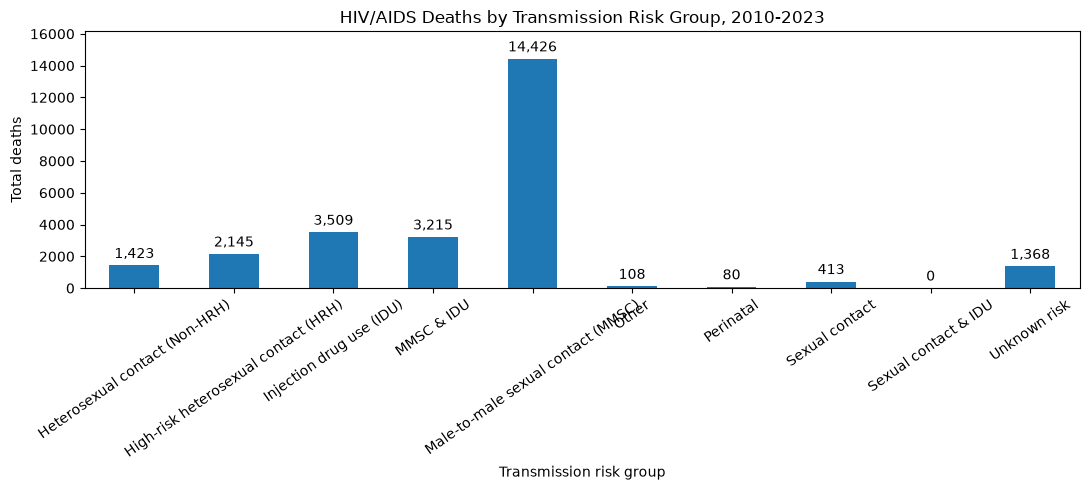

In [12]:
# Death counts by transmission route
ax = transmission.plot.bar(x='Group', y='Count_Deaths', figsize=(11, 5), legend=False)
ax.set_title('HIV/AIDS Deaths by Transmission Risk Group, 2010-2023')
ax.set_xlabel('Transmission risk group')
ax.set_ylabel('Total deaths')
ax.tick_params(axis='x', rotation=35)

for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=3)

ax.set_ylim(0, transmission['Count_Deaths'].max() * 1.12)
plt.tight_layout()
plt.show()

## Linda's plots

I think for our city we can just categorized it by rural and urban. - leah's suggestion

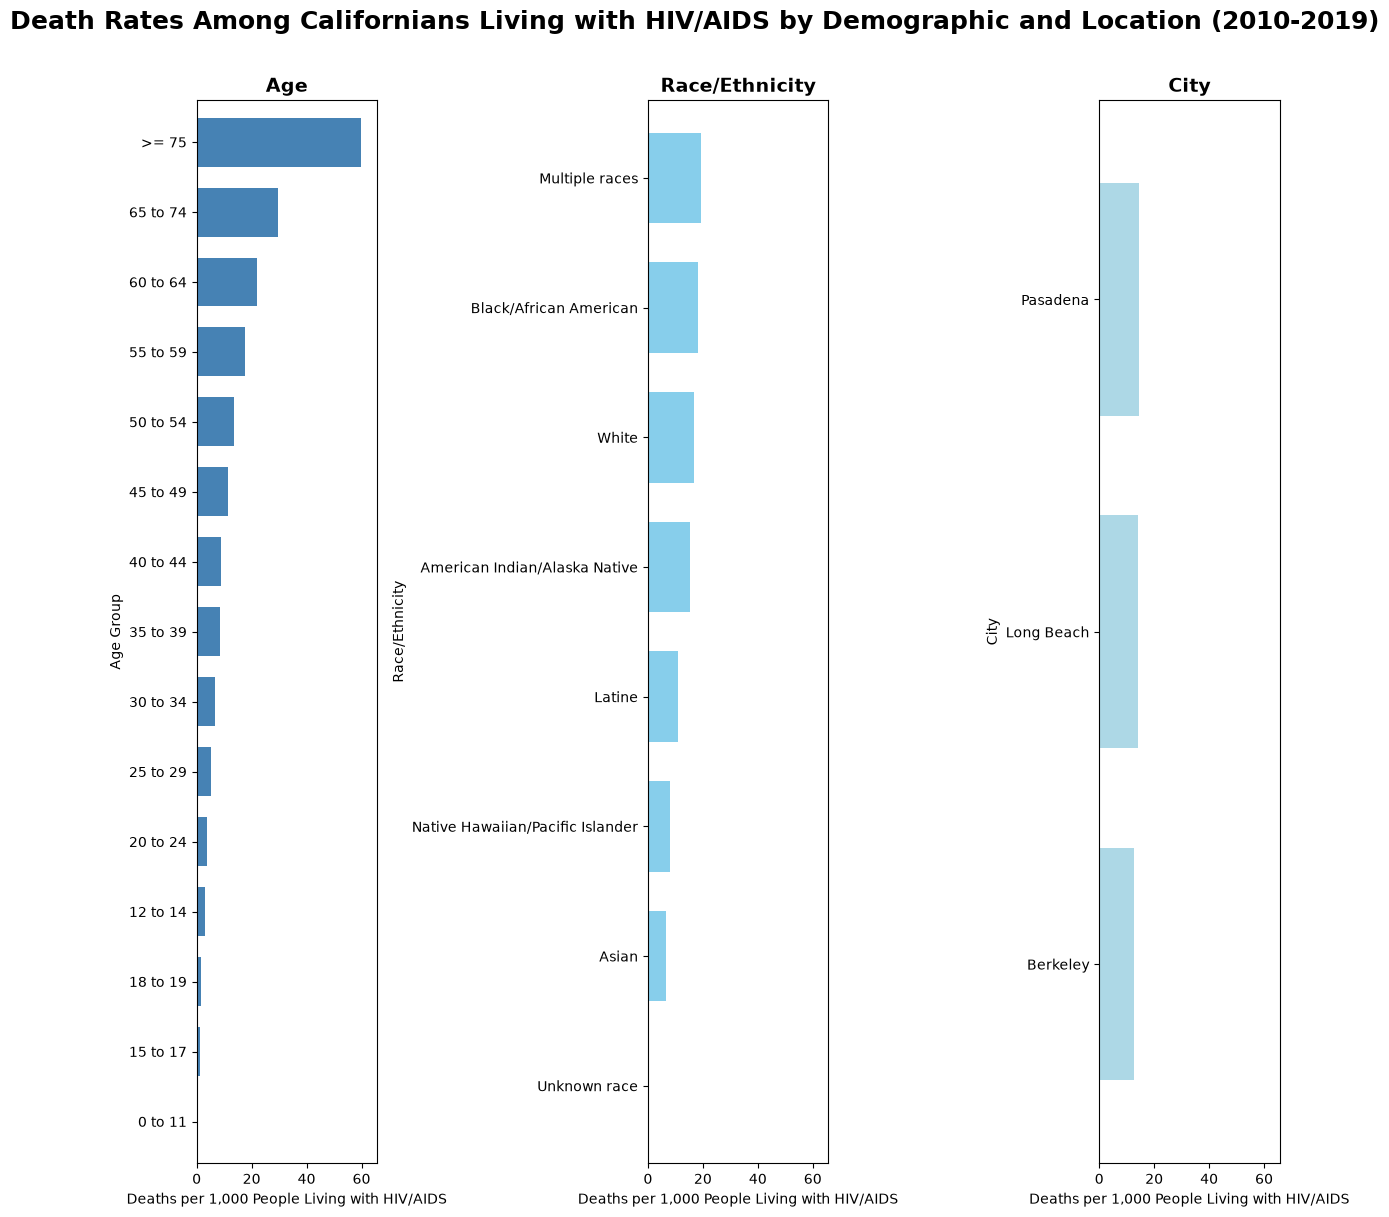

In [9]:
demographics = (
    hiv_aids
        .groupby(['Category', 'Group'])[['Count_Deaths', 'Count_Living']]
        .sum(min_count=1)
)

demographics['Death_Rate'] = (
    demographics.Count_Deaths / demographics.Count_Living * 1000
)

fig, axes = plt.subplots(1, 3, figsize=(12, 12))

colors = ['steelblue', 'skyblue', 'lightblue']

demographics.loc['Age', 'Death_Rate'].sort_values().plot.barh(
    ax=axes[0], color=colors[0], width=0.7
)
axes[0].set_title("Age", fontsize=14, fontweight='bold')
axes[0].set_ylabel("Age Group")

demographics.loc['Race/Ethnicity', 'Death_Rate'].sort_values().plot.barh(
    ax=axes[1], color=colors[1], width=0.7
)
axes[1].set_title("Race/Ethnicity", fontsize=14, fontweight='bold')
axes[1].set_ylabel("Race/Ethnicity")

demographics.loc['City', 'Death_Rate'].sort_values().plot.barh(
    ax=axes[2], color=colors[2], width=0.7
)
axes[2].set_title("City", fontsize=14, fontweight='bold')
axes[2].set_ylabel("City")

for ax in axes:
    ax.set_xlabel("Deaths per 1,000 People Living with HIV/AIDS")

    ax.tick_params(axis='both', labelsize=10)

max_rate = demographics['Death_Rate'].max()

for ax in axes:
    ax.set_xlim(0, max_rate * 1.1)

fig.suptitle(
    "Death Rates Among Californians Living with HIV/AIDS by Demographic and Location (2010-2019)",
    fontsize=18,
    fontweight='bold',
    y=1.01
)

plt.tight_layout()
plt.show()